# LeetCode #336: Palindrome Pairs

https://leetcode.com/problems/palindrome-pairs/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Hash Map with Splits ★ | O(n × k²) | O(n × k) |
| Trie | O(n × k²) | O(n × k) |
| Brute Force | O(n² × k) | O(1) |

## Understanding the Methods
### Hash Map with Splits (Optimal)
Store all words in a hash map (word -> index). For each word, try all possible splits into left and right parts. If the left part is a palindrome and the reverse of the right part exists in the map, we can prepend it. Similarly, if the right part is a palindrome and the reverse of the left part exists, we can append it. This covers all valid pairs. k is the average word length.

### Trie
Build a trie of reversed words. For each word, walk the trie and check for palindrome suffixes/prefixes at each node.

### Brute Force
Check every pair (i,j) and test if concatenation is a palindrome.

## Solutions

### C#

In [ ]:
public class Solution {
    public IList<IList<int>> PalindromePairs(string[] words) {
        var map = new Dictionary<string, int>();
        for (int i = 0; i < words.Length; i++) map[words[i]] = i;
        var result = new List<IList<int>>();

        for (int i = 0; i < words.Length; i++) {
            string w = words[i];
            for (int j = 0; j <= w.Length; j++) {
                string left = w.Substring(0, j);
                string right = w.Substring(j);
                if (IsPalin(left)) {
                    string rev = new string(right.Reverse().ToArray());
                    if (map.ContainsKey(rev) && map[rev] != i)
                        result.Add(new List<int> { map[rev], i });
                }
                if (right.Length > 0 && IsPalin(right)) {
                    string rev = new string(left.Reverse().ToArray());
                    if (map.ContainsKey(rev) && map[rev] != i)
                        result.Add(new List<int> { i, map[rev] });
                }
            }
        }
        return result;
    }

    private bool IsPalin(string s) {
        int l = 0, r = s.Length - 1;
        while (l < r) { if (s[l++] != s[r--]) return false; }
        return true;
    }
}

### Python

In [ ]:
class Solution:
    def palindromePairs(self, words: list[str]) -> list[list[int]]:
        lookup = {w: i for i, w in enumerate(words)}
        result = []

        for i, w in enumerate(words):
            for j in range(len(w) + 1):
                left, right = w[:j], w[j:]
                if left == left[::-1]:
                    rev = right[::-1]
                    if rev in lookup and lookup[rev] != i:
                        result.append([lookup[rev], i])
                if right and right == right[::-1]:
                    rev = left[::-1]
                    if rev in lookup and lookup[rev] != i:
                        result.append([i, lookup[rev]])
        return result

### Go

In [ ]:
func palindromePairs(words []string) [][]int {
    lookup := map[string]int{}
    for i, w := range words {
        lookup[w] = i
    }

    reverse := func(s string) string {
        runes := []rune(s)
        for i, j := 0, len(runes)-1; i < j; i, j = i+1, j-1 {
            runes[i], runes[j] = runes[j], runes[i]
        }
        return string(runes)
    }

    isPalin := func(s string) bool {
        for i, j := 0, len(s)-1; i < j; i, j = i+1, j-1 {
            if s[i] != s[j] { return false }
        }
        return true
    }

    var result [][]int
    for i, w := range words {
        for j := 0; j <= len(w); j++ {
            left, right := w[:j], w[j:]
            if isPalin(left) {
                rev := reverse(right)
                if idx, ok := lookup[rev]; ok && idx != i {
                    result = append(result, []int{idx, i})
                }
            }
            if len(right) > 0 && isPalin(right) {
                rev := reverse(left)
                if idx, ok := lookup[rev]; ok && idx != i {
                    result = append(result, []int{i, idx})
                }
            }
        }
    }
    return result
}

### Rust

In [ ]:
use std::collections::HashMap;

impl Solution {
    pub fn palindrome_pairs(words: Vec<String>) -> Vec<Vec<i32>> {
        let lookup: HashMap<&str, usize> = words.iter().enumerate().map(|(i, w)| (w.as_str(), i)).collect();
        let mut result = Vec::new();

        let is_palin = |s: &str| -> bool {
            let b = s.as_bytes();
            let (mut l, mut r) = (0, b.len().wrapping_sub(1));
            while l < r { if b[l] != b[r] { return false; } l += 1; r -= 1; }
            true
        };

        for (i, w) in words.iter().enumerate() {
            for j in 0..=w.len() {
                let (left, right) = w.split_at(j);
                if is_palin(left) {
                    let rev: String = right.chars().rev().collect();
                    if let Some(&idx) = lookup.get(rev.as_str()) {
                        if idx != i { result.push(vec![idx as i32, i as i32]); }
                    }
                }
                if !right.is_empty() && is_palin(right) {
                    let rev: String = left.chars().rev().collect();
                    if let Some(&idx) = lookup.get(rev.as_str()) {
                        if idx != i { result.push(vec![i as i32, idx as i32]); }
                    }
                }
            }
        }
        result
    }
}

## Example Scenarios

### 1. Common Case — Standard Reverse + Split Pairs
**Input:** `words = ["abcd","dcba","lls","s","sssll"]`
Store `word → index`. For each word try every split; a pair forms when one side is a palindrome and the reverse of the other side exists in the map. `"abcd"+"dcba"`, `"dcba"+"abcd"`, `"s"+"lls"`, `"lls"+"sssll"` all read the same forwards and backwards.
**Output:** `[[1,0],[0,1],[3,2],[2,4]]`

### 2. Slightly Complex — Prepend and Append via Splits
**Input:** `words = ["ab","ba","abc"]`
`"ab"+"ba"="abba"` and `"ba"+"ab"="baab"` are direct reversals; `"abc"+"ba"="abcba"` works because the right part `"c"` is a palindrome and `reverse("ab")="ba"` exists.
**Output:** `[[1,0],[0,1],[2,1]]`

### 3. Edge Case: Time Factor — Quadratic Pair Explosion
**Input:** `words = ["a","aa","aaa"]`
Every word is itself a palindrome, so almost every ordered pair concatenates to a palindrome. With $n$ words of length $k$ the split loop costs $O(n \times k^2)$ and here produces $6$ pairs — the output itself can be large.
**Output:** `[[0,1],[1,0],[1,2],[2,0],[0,2],[2,1]]`

### 4. Edge Case: Space Factor — Empty String Splits
**Input:** `words = ["","a","cc"]`
The empty string has split index $j=0$ only, where `left=""` is a palindrome, so it pairs with every palindrome word in the map on both sides. The map stores all $n$ words at $O(n \times k)$ space.
**Output:** `[[1,0],[0,1],[2,0],[0,2]]`

### 5. Almost-Impossible but Plausible — No Valid Pairs
**Input:** `words = ["abc","def"]`
No split of either word leaves a palindromic side whose complement's reverse is present, so nothing concatenates to a palindrome. The algorithm still scans every split before returning empty.
**Output:** `[]`


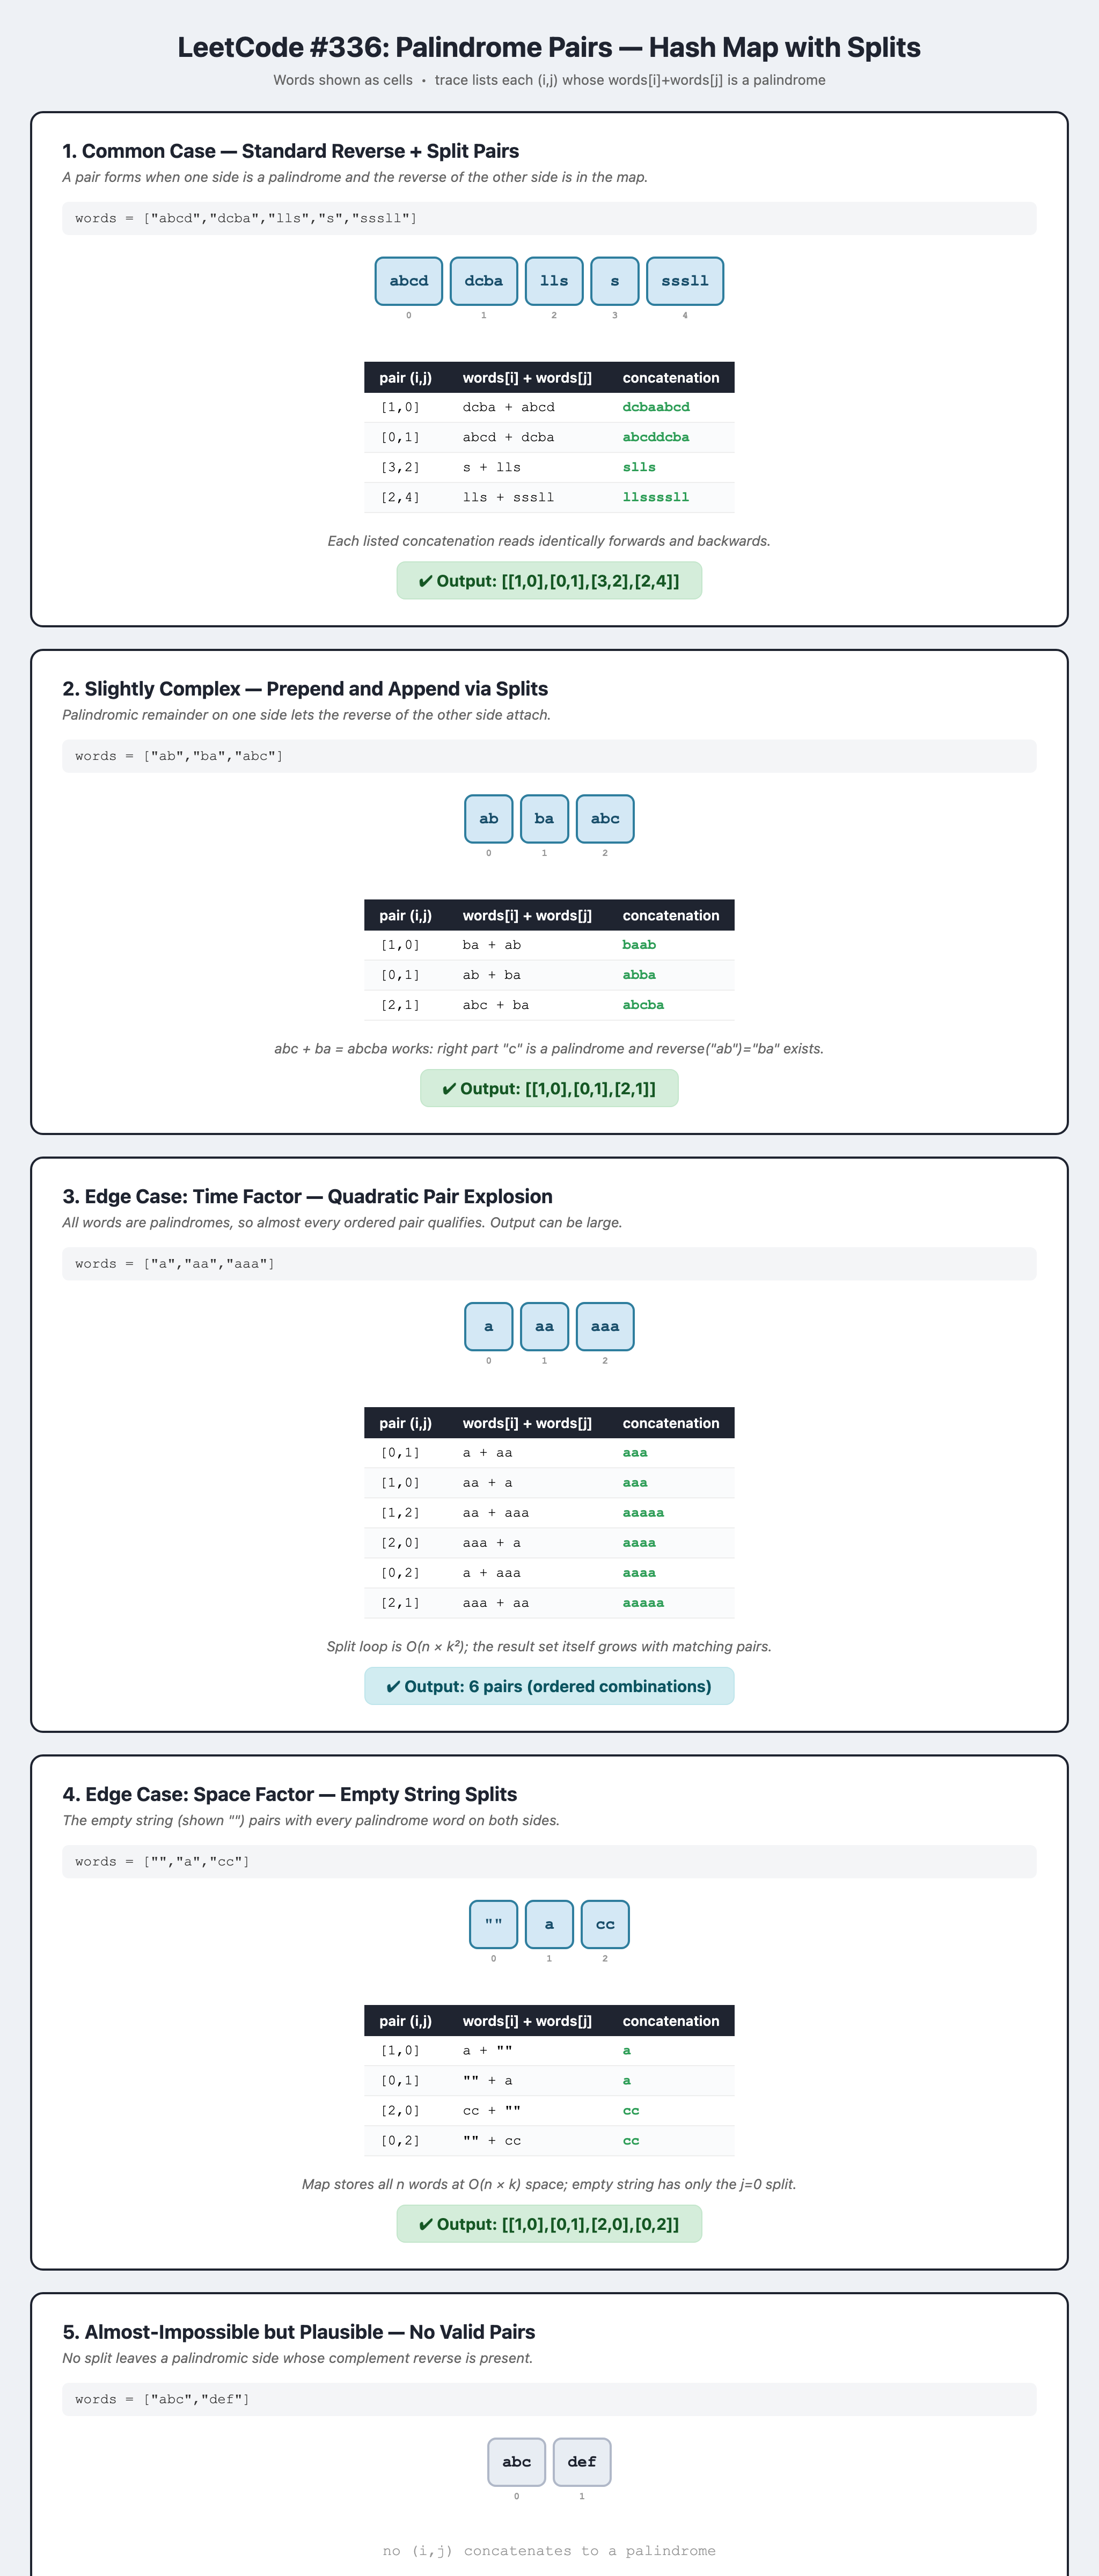